# From a configuration space to a defended decision

A cubesat attitude-control case, read through `tradespace`: a fleet of identical 12U-class satellites whose
power, mass and attitude control are coupled, described by a SysML v2 model. No simulation is run; the fits
and figures are computed from the data.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import SVG, Markdown, display

from demo_support import FIGURES, MODEL, ROOT, draw, excerpt, say, sections

import paper_paths
import case
import sysml_project as views

paper_paths.inline_figures()
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

## 1. Motivation: a decision needs an answer and a justification

Decision analysis has two products: an answer, and a justification an accountable executive can follow and
defend. The justification is the hard product, because the process that turns much data into little must be
recognized, rigorous and reproducible.

A trade study today is mostly a document: a grid, a table, a ranking by weighted criteria, with weights that
are human judgments and open to bias. Systems engineering is moving from document-based to model-based
practice, but the computational alternatives are bespoke and opaque. To displace the document, a method has to
handle the scale, complexity and noise of real data and stay interpretable.

Machine learning offers interpretability at scale, yet a basis that explains variance, as principal component
analysis does, tells a decision-maker little about a trade-off. The question is narrower: which objectives trade against which, at what rates, and which designs are worth choosing among.

## 2. Three layers: decision analysis, machine learning, optimization

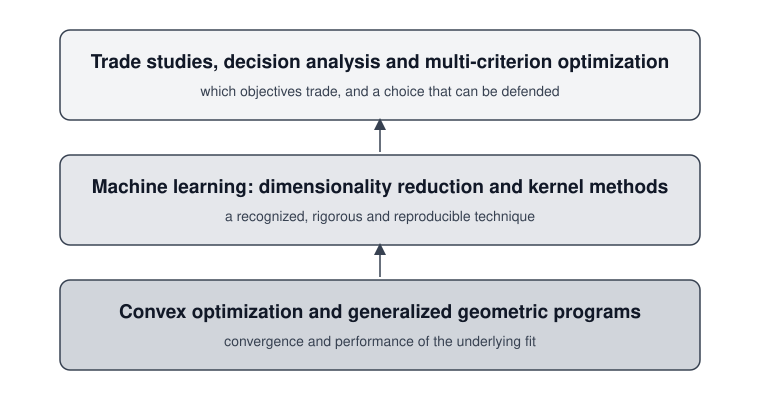

In [2]:
display(SVG(filename=FIGURES / "fig-prior-art-layers.svg"))

Each layer consumes what the one below provides. The decision problem is the SysML v2 model's
requirements and measures of effectiveness, with one stakeholder per objective of the decision. The unsupervised
learning is the fit, which reduces a table of designs to terms and levels without a weight elicited from anyone.
The solver is the convex program of the one-term fit and the alternation of the several-term fit.

## 3. The pipeline

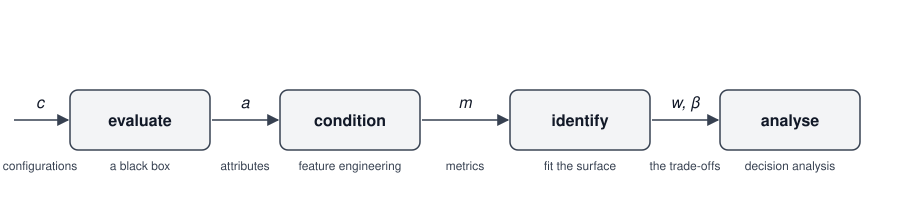

In [3]:
display(SVG(filename=FIGURES / "fig-pipeline.svg"))

A configuration $c$, the design variables, is evaluated into attributes $a$, the evaluation outcomes. The
evaluation is a black box to the method: a simulator behind a system model, a physical test or a human
assessment. Conditioning turns the attributes into metrics $m$, strictly positive and larger is better.
Identification fits the trade-offs, and the analysis reads them into a decision. Configurations in, attributes
out, is the stable surface; everything after it is the package.

## 4. The SysML v2 model

The model of the case is one file, one package, `CubesatTradeSpaceV2`, in seven sections: the first two are the
configuration view and the rest the assessment view.

In [4]:
sections(MODEL)

// 1. CONFIGURATION SPACE (configuration view): what can be chosen
// 2. THE CUBESAT (configuration view): composition and environment
// 3. ACCOUNTING (assessment view): mass, power, energy, inertia, pointing
// 4. SCENARIOS (assessment view): the slew, and a closed-form approximation of it
// 5. REQUIREMENTS, SATISFACTION AND VERIFICATION (assessment view)
// 6. THE EXPERIMENT (assessment view): configuration and measured slew in, attributes out
// 7. NAMED CONFIGURATIONS (configuration view)


**What can be chosen.** Reaction wheels and star trackers are abstract parts with concrete alternatives, one
per literal of an enumeration.

In [5]:
excerpt(MODEL, "abstract part def ReactionWheel", 6)
print("    ...")
excerpt(MODEL, "part def MediumWheel", 6)

    abstract part def ReactionWheel {
        attribute wheelClass : WheelClass;
        attribute maxTorque : TorqueValue;
        attribute maxMomentum : AngularMomentumValue;   // the momentum capacity
        attribute mass : MassValue;
    }
    ...
    part def MediumWheel :> ReactionWheel {
        :>> wheelClass = WheelClass::medium;
        :>> maxTorque = 0.002 [N*m];
        :>> maxMomentum = 0.030 [N*m*s];
        :>> mass = 0.25 [kg];
    }


**What a configuration is.** The cubesat is a composition of parts whose design variables are attributes with
ranges: the panel span, the battery capacity and the fleet size, beside the parts swapped for alternatives.

In [6]:
excerpt(MODEL, "part def Cubesat {", 14)

    part def Cubesat {
        // Design variables (defaults are the baseline configuration).
        attribute panelSpan : LengthValue default = 0.6 [m];
        attribute batteryCapacity : EnergyValue default = 80.0 [W*h];
        attribute fleetSize : Real default = 1.0;   // satellites in the fleet; 1 to 30
        part bus : Bus;
        part panelPlus : SolarPanel { :>> span = Cubesat::panelSpan; }
        part panelMinus : SolarPanel { :>> span = Cubesat::panelSpan; }
        part battery : Battery { :>> capacity = Cubesat::batteryCapacity; }
        part antenna : Antenna;
        part imu : Imu;
        part wheel : ReactionWheel;        // the three identical orthogonal wheels
        part tracker : StarTracker;
        part controller : Controller;


**How it is assessed.** Each traded metric is a calculation of the model, for example the eclipse depth of
discharge, and each requirement states a bound on the same quantity.

In [7]:
excerpt(MODEL, "calc def DepthOfDischarge", 7)
print()
excerpt(MODEL, "requirement def MomentumRequirement", 8)

    calc def DepthOfDischarge {
        doc /* MoP: the eclipse depth of discharge, the eclipse demand with the slew loss energy over
               the battery capacity (the traded metric `depth of discharge`). */
        in c : Cubesat;
        in slewEnergy : EnergyValue;
        return : Real = EclipseDemand(c, slewEnergy) / c.battery.capacity;
    }

    requirement def MomentumRequirement {
        doc /* The peak wheel momentum stays within the wheel class capacity (`momentum_ok`): the
               momentum headroom (the traded metric `momentum headroom`, measured peak momentum
               against the wheel class capacity) is at least 1. */
        subject c : Cubesat;
        in peakMomentum : AngularMomentumValue default = baselineMeasurement.peakMomentum;
        require constraint { MomentumHeadroom(c, peakMomentum) >= 1.0 }
    }


**Where the metrics come from, and what the baseline fails.** The experiment is an `analysis def` that takes
a configuration and the measured slew and returns attributes; `satisfy` and `not satisfy` statements tie each
requirement to the named baseline configuration.

In [8]:
excerpt(MODEL, "analysis def SlewExperiment", 17)
print()
excerpt(MODEL, "satisfy baselineSettled", 10)

    analysis def SlewExperiment {
        subject cubesat : Cubesat;
        in torqueSquaredIntegral : Real;
        in peakTorque : TorqueValue;
        in peakMomentum : AngularMomentumValue;
        in controlEffort : AngularMomentumValue default = baselineMeasurement.controlEffort;
        return attributes = (
            PointingError(cubesat), cubesat.totalMass, controlEffort,
            PowerMargin(cubesat, peakTorque),
            EnergyBalance(cubesat, SlewLossEnergy(torqueSquaredIntegral)),
            PeakSlewPower(cubesat, peakTorque),
            DepthOfDischarge(cubesat, SlewLossEnergy(torqueSquaredIntegral)),
            MomentumHeadroom(cubesat, peakMomentum),
            AvailablePower(cubesat),
            BatteryPeakPowerRatio(cubesat, peakTorque));
    }
    analysis def UnitCostExperiment {

    satisfy baselineSettled by cubesatBaseline;
    satisfy baselineMomentum by cubesatBaseline;
    satisfy baselinePower by cubesatBaseline;
    satisfy baselineDepthOfDis

## 5. The configuration diagram

The assembly view is drawn from the model. A configuration swaps a part for one of its alternatives (the wheel
class, the tracker grade) and tunes a parameter of a part within a range (panel span, battery capacity and the
controller gains Kp and Kd); the fleet size is a seventh variable that is no part, so it is not drawn.

In [9]:
model, by_id = views.load(MODEL)

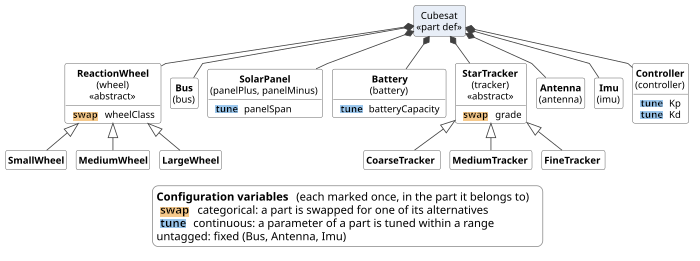

In [10]:
levels = []
display(SVG(draw(views.assembly(model, by_id, "CubesatTradeSpaceV2", caption=levels))))

In [11]:
display(Markdown("\n".join(f"- {line}".replace("*", r"\*") for line in levels[:4])))

- wheelClass (enum WheelClass): small | medium | large
- grade (enum TrackerGrade): coarse | medium | fine
- panelSpan: 0.3 m .. 1 m
- batteryCapacity: 20 W\*h .. 200 W\*h

## 6. The subsystems and requirements diagram

The behavioural view shows how a configuration is assessed: the requirements by functional subsystem
(controls, power and energy, cost, mass), a line from each requirement to the metric it reads, and the lines from
what supplies each metric. A measure of effectiveness (MoE) is one a stakeholder states without knowing the
design; a measure of performance (MoP) is read off the subsystems under the engineer's scenario. Thirteen metrics
are traded.

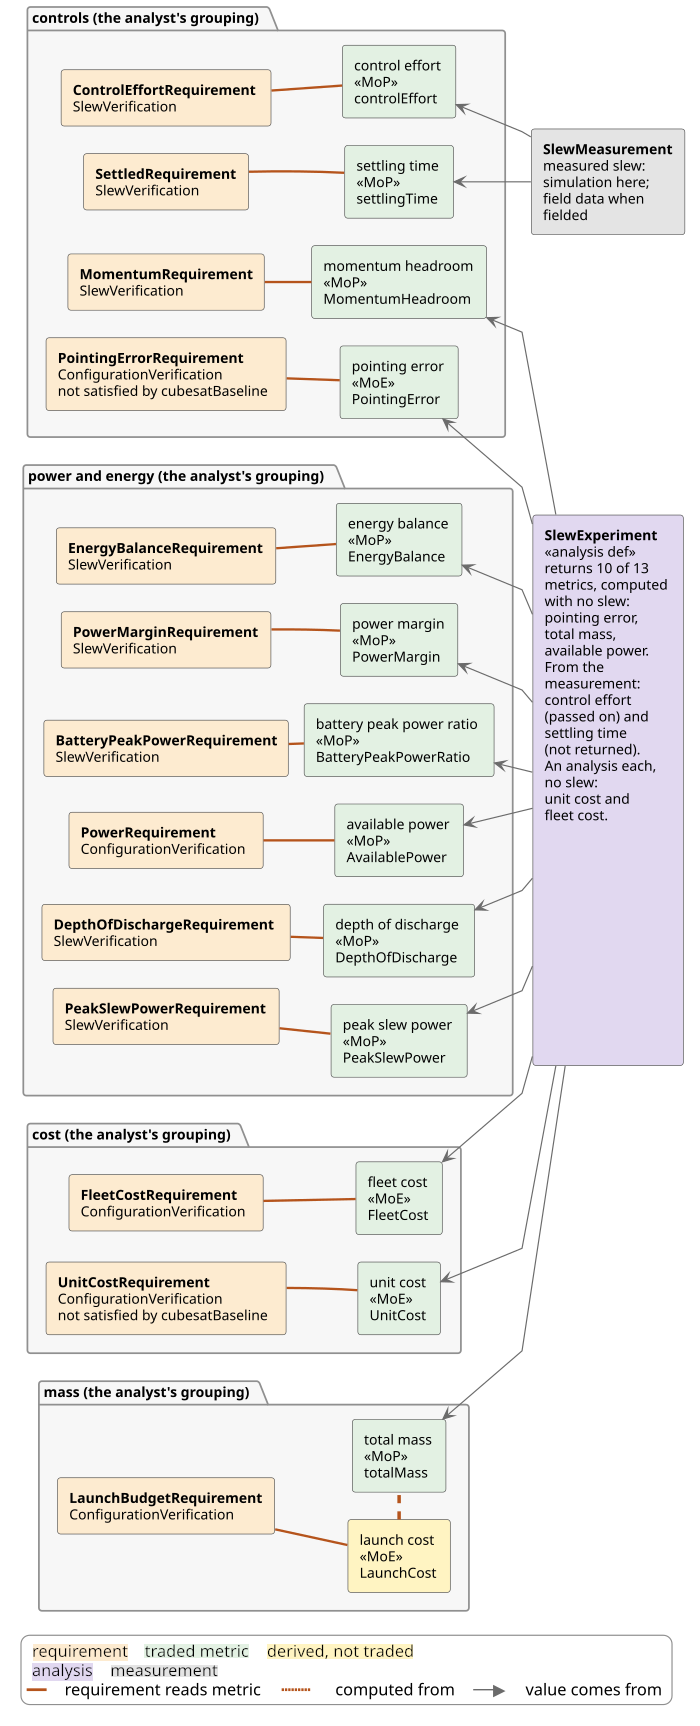

In [12]:
display(SVG(draw(views.behavioural(model, by_id, "CubesatTradeSpaceV2")[0])))

The analysis `SlewExperiment` returns ten of the thirteen traded metrics; the settling time and the control effort
come from the measured slew. The pointing error, the total mass, the available power and the two costs are
computed from the configuration alone, with no slew. Every requirement reads a traded metric. The groups are the
analyst's grouping of the metrics; the model has no such structure.

## 7. The simulations, described and not re-run

Each configuration is evaluated once by the case's oracle. The slew is one 30-degree slew over a 600 s horizon
under a saturating proportional-derivative law, integrated in Python, because the model language cannot
integrate the equations of motion. Every other attribute and the four feasibility verdicts (settled, power
available, momentum within the wheel's capacity, battery depth of discharge within bounds) are computed by the
SysML v2 model's calculations and requirements. The ledger records each run: the model and code hashes, the
command, the output file and its hash, chained entry to entry.

The data hold two regimes that differ in the controller gain's sampled range; the analysis uses the
primary regime.

In [13]:
rows = [json.loads(line) for line in (ROOT / "examples/adcs/experiments/ledger/ledger.jsonl").read_text().splitlines()]
ledger = pd.DataFrame(rows)
latest = ledger[ledger["output_path"].str.contains("data/v2/")].drop_duplicates("output_path", keep="last")
latest.assign(id=latest["id"].str.replace(r"@\d+", "", regex=True))[["id", "evidence_kind", "output_rows", "output_path", "time_utc"]].reset_index(drop=True)

,id,evidence_kind,output_rows,output_path,time_utc
0,v2-primary,simulation,3000,examples/adcs/data/v2/adcs_designs_cubesat_gains.csv,2026-11-12T01:28:26Z
1,v2-baseline,simulation,3000,examples/adcs/data/v2/adcs_designs_cubesat.csv,2026-11-12T01:58:45Z
2,v2-check-predictions,simulation,3,examples/adcs/data/v2/check_predictions_cubesat.csv,2026-11-17T15:06:44Z
3,v2-check-designs,simulation,6,examples/adcs/data/v2/check_designs_cubesat.csv,2026-11-17T15:06:44Z


In [14]:
study = case.load_study("primary")
from generate_findings import datasets_sentence

say(datasets_sentence(study, case.load_study("stock")))

The primary regime evaluates 3,000 designs and keeps 2,134 as feasible; the baseline regime evaluates 3,000 and keeps 2,355. Each design carries thirteen attributes. The designs are drawn at random, 3,000 per regime: a design choice of the case, since the method assumes nothing about how they were drawn.

## 8. The fit with `tradespace`

Conditioning orients each attribute so larger is better, shifts and scales it, and keeps the map invertible and
the count: thirteen attributes make thirteen metrics.

In [15]:
case.conditioning_table(study)[["orientation", "raw min", "raw max", "m min", "m max"]]

,orientation,raw min,raw max,m min,m max
settling time,reciprocal,7.111256,5.980907e+02,0.045700,8.814100
pointing error,reciprocal,0.000602,8.642060e-03,0.314937,6.352452
total mass,reciprocal,11.859512,1.627544e+01,0.065027,8.610559
control effort,reciprocal,0.008614,5.973831e-01,0.036944,10.859370
power margin,direct,6.508694,6.585201e+01,0.085111,6.593192
energy balance,direct,0.953876,5.623653e+01,0.041038,4.820727
peak slew power,reciprocal,1.304500,7.400000e+00,0.276192,3.856196
depth of discharge,reciprocal,0.039946,2.997128e-01,0.181289,5.884704
momentum headroom,direct,1.000411,2.118558e+01,0.283468,64.334581
available power,direct,11.057410,6.890030e+01,0.147903,6.980779


The fit is the package's scikit-learn estimator. Its temperature, the sharpness of the soft maximum, is selected
so that a target fraction of designs lies beyond the fitted reference surface.

In [16]:
fit = case.fit_study(study)  # K = 1: the monomial frontier, temperature selected
fits = case.k_fits(study)  # K = 1, 2, 3

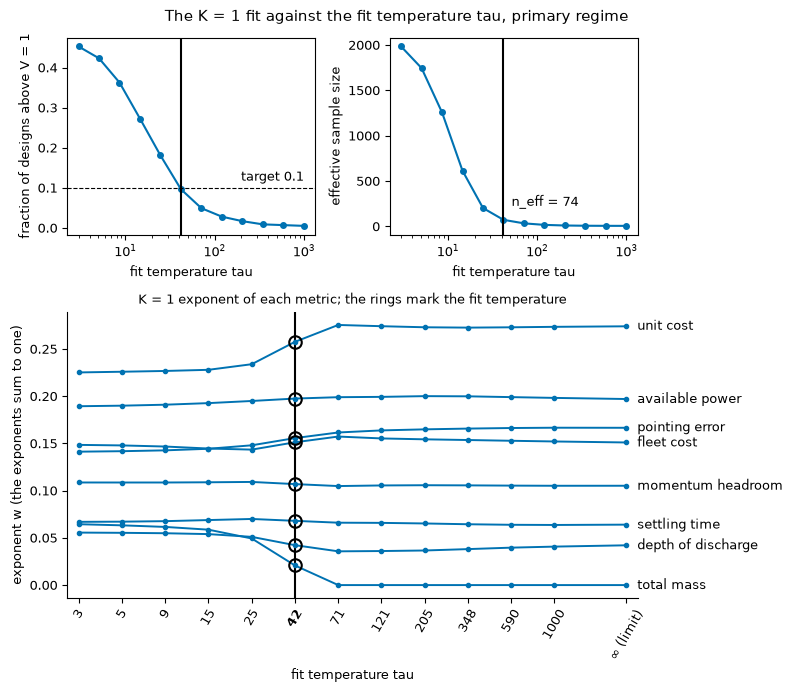

In [17]:
case.tau_sweep_lines_figure(study, fit);

In [18]:
from generate_findings import temperature_sentence

say(temperature_sentence(study, fit))

The fit temperature is tau = 41.7: a fraction 0.098 of designs lies above V = 1 (the target is 0.10), the band 1/tau is 0.0240 and the effective sample size is 73.6 designs. The effective sample size is the inverse sum of squares of the support weights, the softmax weights of the designs in the fit: the designs the soft maximum weighs as if equally, so the exponents at the fit temperature rest on about that many of the 2,134 designs. The contending set holds with the target fraction halved or doubled.

The trade-off report of the one-term fit names the metrics that contend and the largest exponents.

In [19]:
case.trade_off_table(study, fit).rename(columns={"n_lemma": "metrics in the term"})

,term,metrics in the term,near-frontier,contending set,largest exponents
0,1,7,238,"unit cost, available power, pointing error, fleet cost, momentum headroom, settling time, depth of discharge","unit cost 0.257, available power 0.197, pointing error 0.156"


## 9. Exploratory analysis for choosing among alternatives

### 9.1 Which designs are feasible, and what the requirements cut

In [20]:
case.feasibility_table(study)

,condition,fails alone,removed in this order,remaining
0,settled,71,71,2929
1,power_ok,0,0,2929
2,momentum_ok,540,473,2456
3,dod_ok,389,322,2134
4,all attributes positive,0,0,2134


In [21]:
from generate_findings import nondominated_sentence

say(nondominated_sentence(study))

Of 2,134 feasible cubesat designs, the nondominated set (on the conditioned metrics, larger is better) holds 236 on 4 attributes (settling time, pointing error, control effort and total mass) and 2,134 on all 13.

**For the choice.** The four feasibility conditions remove the designs that cannot be built to work. Among
the 2,134 that remain, dominance on thirteen metrics keeps every one, so it does not narrow the choice. The fit
supplies what dominance cannot: what contends, at what rates, and where each design sits.

### 9.2 The contending set and the tension matrix

In [22]:
from generate_findings import k1_sentence

say(k1_sentence(study, fit))

At K = 1 the exact-maximum fit has 7 contending metrics across controls, power and energy, plus cost: unit cost, available power, pointing error, fleet cost, momentum headroom, settling time and depth of discharge contend, with exponents at the fit temperature from 0.04 to 0.26. At the fit temperature total mass also carries 0.02 and is not in the contending set, which is the exact maximum's support. 

In [23]:
fit_case = fits[case.CASE_K]  # K = 2: the two-term fit
case.trade_off_table(study, fit_case).rename(columns={"n_lemma": "metrics in the term"})

,term,metrics in the term,near-frontier,contending set,largest exponents
0,1,8,127,"peak slew power, pointing error, unit cost, available power, fleet cost, momentum headroom, settling time, depth of discharge","peak slew power 0.426, pointing error 0.206, unit cost 0.122"
1,2,7,45,"unit cost, available power, fleet cost, momentum headroom, pointing error, settling time, depth of discharge","unit cost 0.250, available power 0.216, fleet cost 0.142"


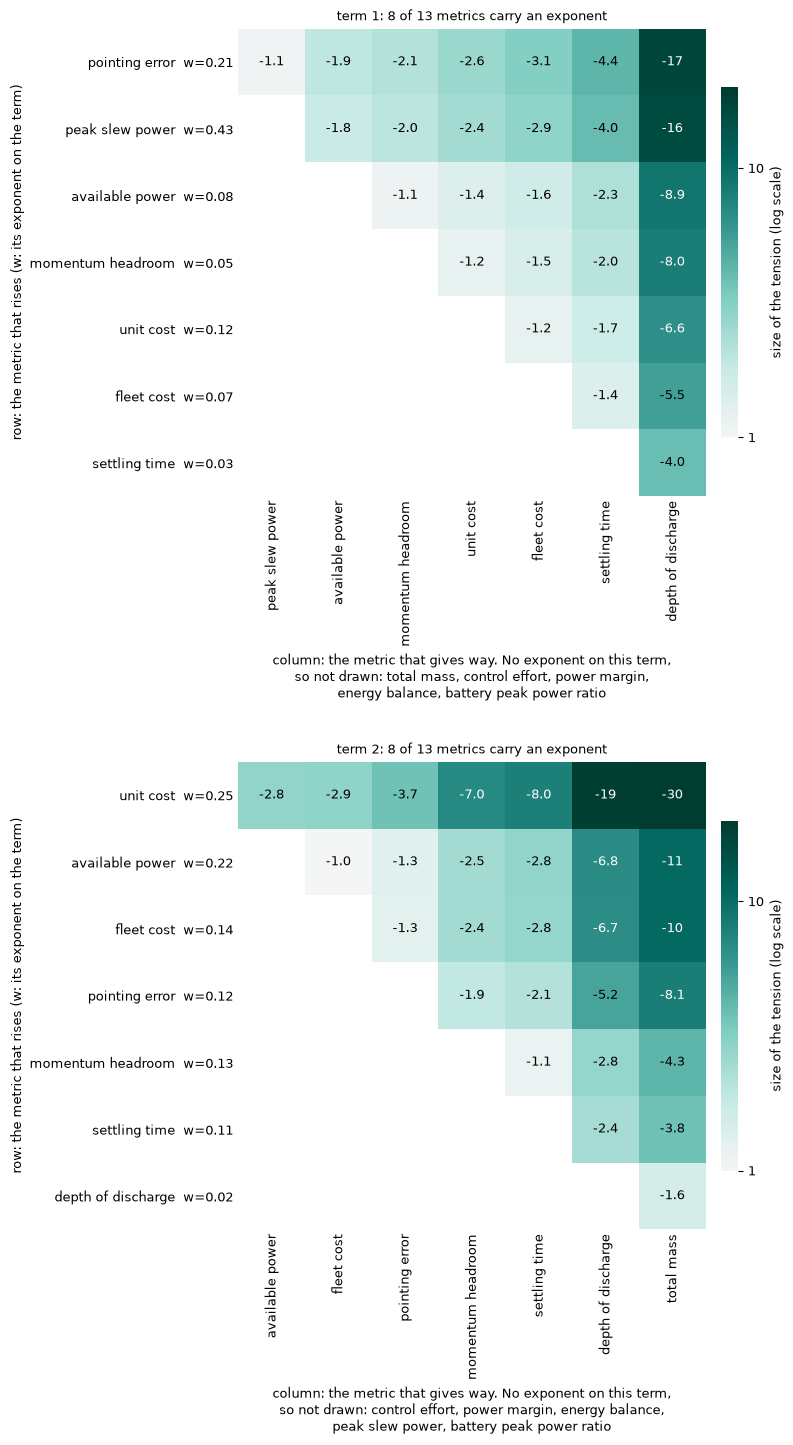

In [24]:
case.tension_matrix_figure(study, fit_case, triangle="upper", order="tension");

In [25]:
from generate_findings import elasticity_sentence, terms_sentence

say(terms_sentence(study, fits))
say(elasticity_sentence(study, fits))

The K = 2 terms have contending sets (exact-maximum supports) of 8 and 7 metrics; peak slew power, absent from the K = 1 set, carries the largest exponent of term 1 (0.43). At the fit temperature total mass also carries 0.0064 on term 2, so it is drawn in that term's tension matrix without being in its contending set. The term shares are 0.74 and 0.26 for terms 1 and 2.

On term 2 the elasticity between unit cost and available power is -0.9, the ratio of their exponents: along the term, one percent gained in available power is 0.9 percent given up in unit cost. The tension matrix states the same trade per unit of the conditioned metrics at the term's balanced point, not per percent, so its cell for the pair reads -2.8. Term 1's two leading metrics, peak slew power and pointing error, are stepped by the swaps of the tracker grade and the wheel class, so its elasticity is read across the swapped parts' alternatives rather than along one continuous trade.

**For the choice.** A term names the metrics that contend on it and the rate at which each gives way to another.
That is the justification an executive can follow: gaining available power costs unit cost at a stated rate, and
the swaps of the tracker grade and the wheel class step the other term. No weight was elicited from anyone.

### 9.3 Where each term leads

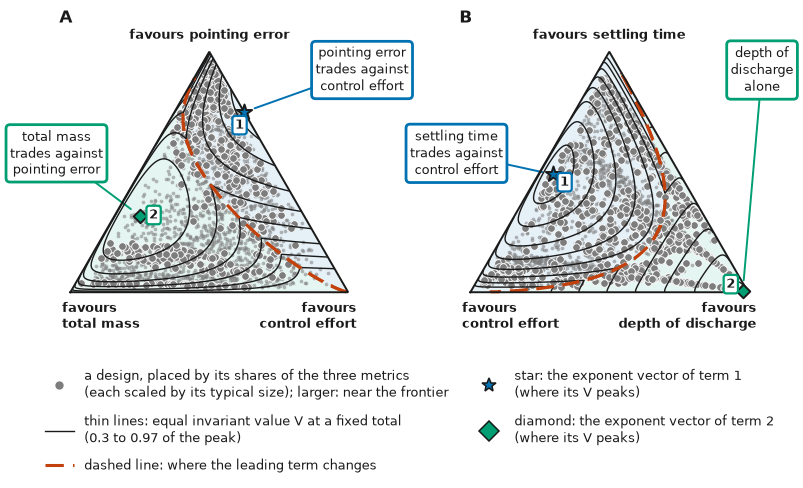

In [26]:
case.ternary_pair_figure();

**For the choice.** A term's marker is its exponent vector, not a design. Its position shows which two of the
three metrics the term trades, and the dashed line is where the leading term, and so the answer, changes from one
term to the other.

### 9.4 The fleet-size trade

When stakeholders' economic objectives can be computed from the model at hand or from a budgeting or forecast
model, the same system can be read from the vantage point of the principals who make the financial decision, and
the reading stays grounded in the same model and the data the fit was made on. Here the fleet cost is
the unit cost times the fleet size, and the coverage probability is computed from the fleet size and the pointing
error; the sponsor, the manufacturer and the operator sit at the corners. The fit is repeated on these three
objectives alone.

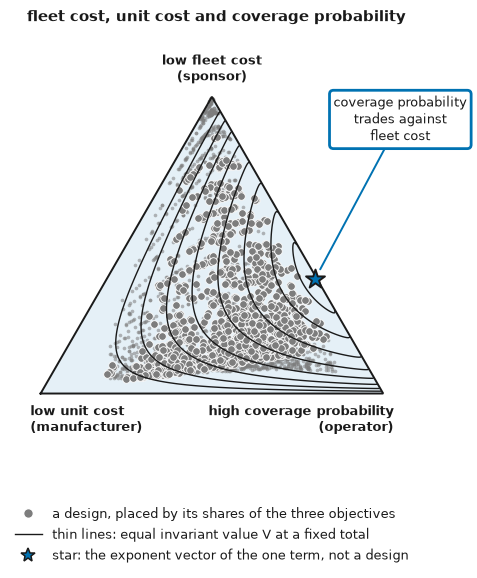

In [27]:
case.fleet_ternary_figure();

In [28]:
from generate_findings import fleet_refit_sentence

say(fleet_refit_sentence())

On all 2,134 feasible designs fleet cost over unit cost times fleet size is one to within 6e-09. The two-term refit puts on fleet cost and coverage probability 0.14 and 0.86 in term 1 and 0.54 and 0.46 in term 2, and 0.000 on unit cost in both, so both terms lie on the one-term fit's edge.

**For the choice.** The decision gives each of three objectives to one stakeholder: the fleet cost to the
sponsor, the unit cost to the manufacturer and the coverage probability to the operator. They do not stay three
trade-offs. Fleet cost is unit cost times fleet size, so the sponsor's objective rides on the manufacturer's and on
the fleet size, and the fit names one dilemma between fleet cost and coverage probability, with unit cost nearly
flat.

### 9.5 The requirements, read after the fit

In [29]:
from generate_findings import requirements_sentence

say(requirements_sentence(study, fit))

Applied after the K = 1 fit as constraints on the solution space, the six requirements exclude 178 of its 238 near-frontier designs jointly; one at a time: peak slew power 108, control effort 95, unit cost 64, fleet cost 57, total mass 12 and pointing error 8.

**For the choice.** Fitting first and reading the requirements after is the unconstrained-then-constrained
reading of a trade study. The requirements are the model's bounds and cut the near-frontier designs
unevenly, so the counts say which requirement costs the most designs.

### 9.6 Propose, predict, check

The surrogate is a regressor from configuration to chart coordinates: a design's position along the fitted
reference surface, plotted as Z0 against Z1, then Z0 against Z2. Each dot is a design, ringed when it lies near the
surface. Each numbered proposal is an open circle where the surrogate predicted it and a pink diamond where it was
measured.

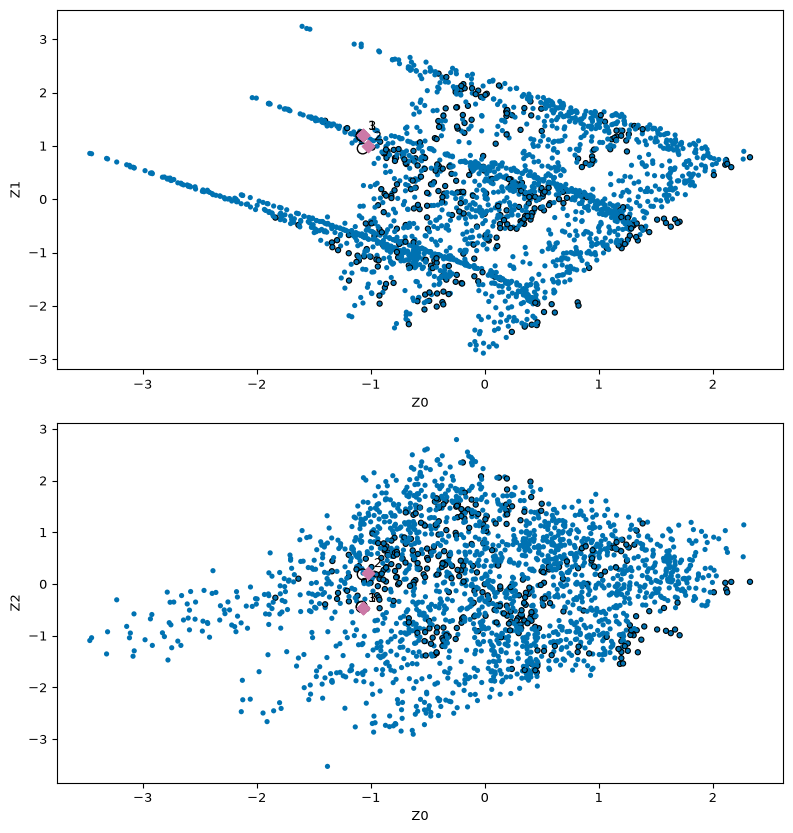

In [30]:
reg = case.fit_regressor(study)  # the surrogate: configuration to chart coordinates
pc = case.predict_check(study, reg)
case.predict_check_figure(study, reg)
plt.gcf().axes[1].set_ylabel("Z2");

In [31]:
from generate_findings import predict_check_sentence

say(predict_check_sentence(pc, reg))

Of 3 proposals, the predicted energy differential lies within the regressor's own band 1/tau = 0.0935 (its four-metric fit's, not the case's) of the measured one for 3, and the predicted position within that band for 3; position errors run from 0.2 to 0.8 bands.

**For the choice.** The surrogate proposes configurations for regions of the chart no design occupies, and the
proposals are then measured. The three proposals fail the depth-of-discharge condition: they reached the four-metric fitted
reference surface by spending the battery. A prediction is a conjecture until it is measured, and the check
is what keeps the proposal honest.

### 9.7 The decision

In [32]:
from generate_findings import decision, decision_sentence, decision_table

dec = decision(study, fits)
say(decision_sentence(dec))

**The decision.** The requirements and the fits cut 2,134 feasible designs to a shortlist of 28 that pass all six requirements and lie in the near-frontier band of both fits. On it the manufacturer and the operator pick the same fleet: 25 medium-wheel, medium-tracker satellites at 234,000 USD each, 5.85 M USD for the fleet and a coverage probability of 0.98. The unit cost falls and the coverage probability rises with the fleet size. The sponsor picks 4 small-wheel, medium-tracker satellites at 1.13 M USD, with a coverage probability of 0.46. What remains is the question the fit names, and it is the executives': how much fleet cost a gain in coverage probability is worth. Of the 17 shortlisted designs that no other beats on both, the fleet of 10 small-wheel, medium-tracker satellites at 2.88 M USD, with a coverage probability of 0.76, has the smallest larger shortfall on the two, each scaled from its best to its worst on the shortlist.

In [33]:
Markdown(decision_table(dec).replace("| level |", "| energy level (log V) |"))

| rule | configuration | fleet cost (USD) | unit cost (USD) | coverage probability | energy level (log V) |
|---|---|---|---|---|---|
| baseline configuration | medium wheel, medium tracker, fleet 1 | 461,360 | 461,360 | 0.032 | -0.330 |
| sponsor: least fleet cost | small wheel, medium tracker, fleet 4 | 1,127,465 | 281,866 | 0.456 | +0.016 |
| manufacturer: least unit cost | medium wheel, medium tracker, fleet 25 | 5,846,300 | 233,852 | 0.979 | -0.022 |
| operator: largest coverage probability | medium wheel, medium tracker, fleet 25 | 5,846,300 | 233,852 | 0.979 | -0.022 |
| between sponsor and operator | small wheel, medium tracker, fleet 10 | 2,882,089 | 288,209 | 0.762 | +0.001 |

**For the choice.** The energy level, log V, is positive beyond the fitted reference surface. No rerun answers
the executives' question, and the justification they receive is reproducible from the data.

## 10. Closing: the package and closed-loop design-space search

The fitted invariant value $V$ is an energy-like function of the metrics. A design that improves every metric
raises $V$, and a maximizer of $V$ over a set of designs is weakly Pareto-efficient. On the chart, the level of a
design is $\log V$, its energy differential; the package returns it as `score_samples`.

$V$ is a function of the metrics, and a search chooses configurations. The regressor from configuration to
metrics, `TradeSpaceRegressor`, is the surrogate that makes $V$ a function of the design: a configuration is
mapped to its predicted chart point and level, and a search can rank configurations by it.

The outer loop is a direction. A chart point without a datum pulls back to a proposal, a configuration chosen by
a selection rule and a conjecture until it is built and measured. An outer loop would evaluate the proposals,
append the rows and refit. The package provides the regressor and the lookup of a sampled point's configuration; the
cubesat case's own code adds a pooled proposal and its check. The loop itself, with its selection rule, is future work; when it
converges is not studied.